## **9. Write and execute programs for image frequency domain filtering.**

a. Apply FFT on given image

b. Perform low pass and high pass filtering in frequency domain

c. Apply IFFT to reconstruct image

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage import data

In [2]:
img = data.camera()

 Apply FFT on given image

(np.float64(-0.5), np.float64(511.5), np.float64(511.5), np.float64(-0.5))

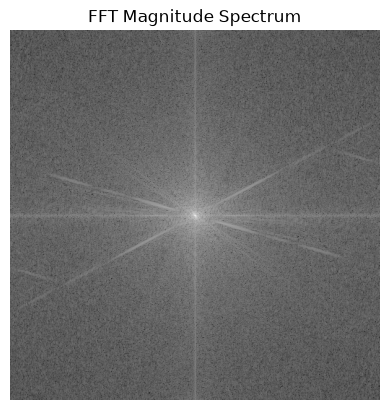

In [3]:
f = np.fft.fft2(img)
fshift = np.fft.fftshift(f)
# Magnitude Spectrum for display (Log scale)
magnitude_spectrum = 20 * np.log(np.abs(fshift))
    
rows, cols = img.shape
crow, ccol = rows // 2, cols // 2
plt.imshow(magnitude_spectrum, cmap='gray')
plt.title("FFT Magnitude Spectrum")
plt.axis('off')

Perform Low Pass and High Pass Filtering

In [4]:
# Create Low Pass Filter Mask (Circle in center)
mask_lp = np.zeros((rows, cols), np.uint8)
r = 30 # Radius
cv2.circle(mask_lp, (ccol, crow), r, 1, -1)
    
# Create High Pass Filter Mask (Inverse of Low Pass)
mask_hp = 1 - mask_lp
    
# Apply Masks
fshift_lp = fshift * mask_lp
fshift_hp = fshift * mask_hp


(np.float64(-0.5), np.float64(511.5), np.float64(511.5), np.float64(-0.5))

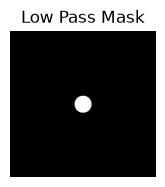

In [5]:
plt.subplot(2, 3, 4)
plt.imshow(mask_lp, cmap='gray')
plt.title("Low Pass Mask")
plt.axis('off')

Apply IFFT to reconstruct image

In [6]:
# Reconstruct Low Pass
f_ishift_lp = np.fft.ifftshift(fshift_lp)
img_back_lp = np.fft.ifft2(f_ishift_lp)
img_back_lp = np.abs(img_back_lp)
    
# Reconstruct High Pass
f_ishift_hp = np.fft.ifftshift(fshift_hp)
img_back_hp = np.fft.ifft2(f_ishift_hp)
img_back_hp = np.abs(img_back_hp)

(np.float64(-0.5), np.float64(511.5), np.float64(511.5), np.float64(-0.5))

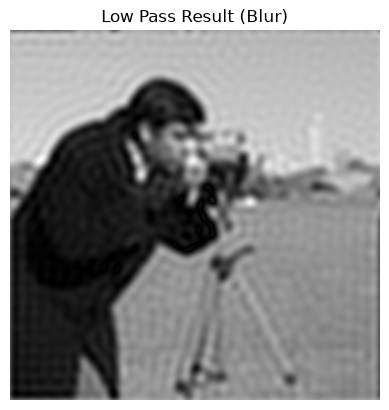

In [7]:

plt.imshow(img_back_lp, cmap='gray')
plt.title("Low Pass Result (Blur)")
plt.axis('off')

(np.float64(-0.5), np.float64(511.5), np.float64(511.5), np.float64(-0.5))

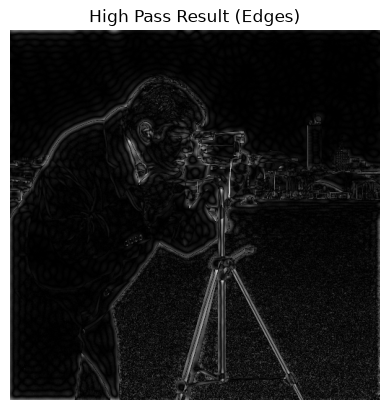

In [8]:
plt.imshow(img_back_hp, cmap='gray')
plt.title("High Pass Result (Edges)")
plt.axis('off')